# Lab 1-06：多模態 API——圖片、聲音也能放進請求

**目標**：用同一套 Chat API 的寫法送出圖片，再走一遍「文字 → 圖片」「文字 → 語音 → 文字」，最後用本機的 Whisper 做同樣的語音轉文字。

**你會學到**
- 圖片怎麼放進 `messages`：`content` 從字串變成陣列
- 圖片為什麼也要算 token，以及怎麼省
- 文字轉語音（TTS）、語音轉文字（STT）、生成圖片各是哪個端點
- 聲音進模型前長什麼樣：log-mel 頻譜圖
- 本機 Whisper 與雲端轉錄的差距

**前置**：雲端部分需要 `OPENAI_API_KEY`（在 `.env` 填入）。沒有金鑰也能跑完：雲端步驟會印出說明並略過，
已經生成好的圖片和音檔放在 `data/`，後面的本機步驟照樣能用。本機轉錄會下載 `openai/whisper-tiny`（約 150MB）。

這本跑一次的雲端費用：生成 1 張低畫質圖、1 次看圖、1 段語音、1 次轉錄，合計約幾美分（以官方定價頁為準）。
圖片和音檔若已存在就直接讀檔，不會重打 API。

**對應投影片**：「開放權重與商業 API」「選型：商業 API 模型」「messages JSON 實物」

![多模態 API 的四個端點：chat.completions、images.generate、audio.speech、audio.transcriptions](images/multimodal_endpoints.jpg)

*圖：四種能力是四個端點，同一個 client。Step 7 產生的語音再送進 Step 9、10 轉回文字（朱紅的閉環），才知道轉錄準不準；本機版用 Whisper（Step 9）。*

## Step 1：準備——金鑰有沒有，決定哪些步驟會跑

四種能力對應四個端點，都在同一個 `client` 底下：

| 方向 | 端點 | 這本用的模型 |
|---|---|---|
| 文字＋圖片 → 文字 | `chat.completions` | `gpt-5.4-nano` |
| 文字 → 圖片 | `images.generate` | `gpt-image-2` |
| 文字 → 語音 | `audio.speech` | `gpt-4o-mini-tts` |
| 語音 → 文字 | `audio.transcriptions` | `gpt-4o-mini-transcribe`；本機 `whisper-tiny` |

模型名稱會隨時間更新，以 OpenAI 官方文件為準。

In [1]:
import base64
import os
import time
from pathlib import Path

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
DATA = Path("data")
HAS_KEY = bool(os.getenv("OPENAI_API_KEY"))
client = OpenAI() if HAS_KEY else None

VISION_MODEL = "gpt-5.4-nano"
IMAGE_MODEL = "gpt-image-2"
TTS_MODEL = "gpt-4o-mini-tts"
STT_MODEL = "gpt-4o-mini-transcribe"


def skip(what: str) -> None:
    print(f"沒有 OPENAI_API_KEY，略過「{what}」。要跑的話在 .env 加上 OPENAI_API_KEY=...")


print("有雲端金鑰嗎？", HAS_KEY)  # 只印有沒有，不印金鑰本身

有雲端金鑰嗎？ True


## Step 2：先自己做一張圖

要測「模型看不看得懂圖」，最好用一張**答案我們自己知道**的圖。這裡畫一張虛構的長條圖：千陽號一週的漁獲。

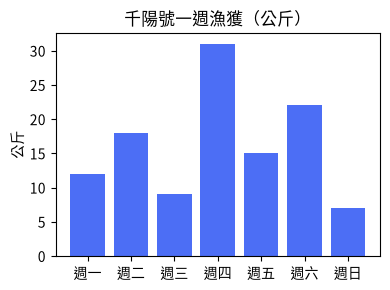

data/fish_chart.png 16 KB


In [2]:
import matplotlib.pyplot as plt
from course_utils.viz import setup_cjk

setup_cjk()
days = ["一", "二", "三", "四", "五", "六", "日"]
fish_kg = [12, 18, 9, 31, 15, 22, 7]  # 虛構數字；正確答案：週四最多，31 公斤

fig, ax = plt.subplots(figsize=(4, 3), dpi=100)
ax.bar([f"週{d}" for d in days], fish_kg, color="#4c6ef5")
ax.set_title("千陽號一週漁獲（公斤）")
ax.set_ylabel("公斤")
plt.tight_layout()
chart_path = DATA / "fish_chart.png"
fig.savefig(chart_path)
plt.show()
print(chart_path, f"{chart_path.stat().st_size / 1024:.0f} KB")

## Step 3：圖片怎麼放進 messages

之前 `content` 是一個字串。要放圖片時，`content` 改成**陣列**，每個元素是一塊內容：文字一塊、圖片一塊。
圖片有兩種給法：
- **網址**：`"url": "https://..."`，由服務商自己去下載（圖片必須是公開的）
- **base64**：把檔案編碼成一長串文字，前面加 `data:image/png;base64,`，本機檔案用這個

In [3]:
import json


def to_data_url(path: Path) -> str:
    mime = "image/png" if path.suffix == ".png" else "image/jpeg"
    return f"data:{mime};base64," + base64.b64encode(path.read_bytes()).decode()


chart_url = to_data_url(chart_path)
message = {
    "role": "user",
    "content": [
        {"type": "text", "text": "哪一天漁獲最多？大約幾公斤？"},
        {"type": "image_url", "image_url": {"url": chart_url}},
    ],
}
# base64 很長，只印開頭
preview = json.dumps(message, ensure_ascii=False, indent=2).replace(chart_url, chart_url[:40] + "...")
print(preview)
print(f"這張圖的 base64 有 {len(chart_url):,} 個字元")

{
  "role": "user",
  "content": [
    {
      "type": "text",
      "text": "哪一天漁獲最多？大約幾公斤？"
    },
    {
      "type": "image_url",
      "image_url": {
        "url": "data:image/png;base64,iVBORw0KGgoAAAANSU..."
      }
    }
  ]
}
這張圖的 base64 有 21,566 個字元


用網址的寫法只差在 `url` 換成公開的圖片網址，其他完全一樣：

```python
{"type": "image_url", "image_url": {"url": "https://example.com/ship.jpg", "detail": "low"}}
```

`detail` 可以是 `low`、`high` 或 `auto`：`low` 先把圖縮小再看，便宜很多，但小字會看不清楚。

## Step 4：圖片也是 token

模型看圖的方式跟你學過的 Vision Transformer 一樣：把圖切成小方格（patch），每格變成一個向量，跟文字 token 排在同一條序列裡。
所以**圖越大，token 越多，越貴**。有些模型按 32×32 的小格計費，有些按 512×512 的 tile 計費，細節看各家定價頁。
下面把我們的圖切成 32×32 的格子，數一數有幾格。

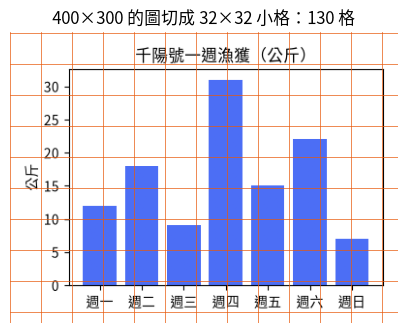

400×400 →   169 格
1024×1024 →  1024 格
2048×2048 →  4096 格


In [4]:
import math

from PIL import Image

img = Image.open(chart_path)
w, h = img.size
patch = 32
n_patch = math.ceil(w / patch) * math.ceil(h / patch)

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.imshow(img)
for x in range(0, w, patch):
    ax.axvline(x, color="#e8590c", lw=0.5)
for y in range(0, h, patch):
    ax.axhline(y, color="#e8590c", lw=0.5)
ax.set_title(f"{w}×{h} 的圖切成 32×32 小格：{n_patch} 格")
ax.axis("off")
plt.show()

for side in [400, 1024, 2048]:
    print(f"{side}×{side} → {math.ceil(side / patch) ** 2:>5} 格")

一張 2048×2048 的照片就是幾千格，比一整頁文字還多。實務上先把圖縮到看得清楚就好的大小再送，或用 `detail: "low"`。

## Step 5：文字 → 圖片

生成圖片用的是另一個端點 `images.generate`。回來的是 base64 編碼的圖檔，自己解碼存檔。
品質選 `low`、尺寸選 1024×1024 最便宜；檔案已存在就不重生，省錢也讓結果固定。

生成完成，花了 11.5 秒，用量：Usage(input_tokens=36, input_tokens_details=UsageInputTokensDetails(image_tokens=0, text_tokens=36), output_tokens=196, total_tokens=232, output_tokens_details=UsageOutputTokensDetails(image_tokens=196, text_tokens=0))
data/gen_ship.jpg：193 KB


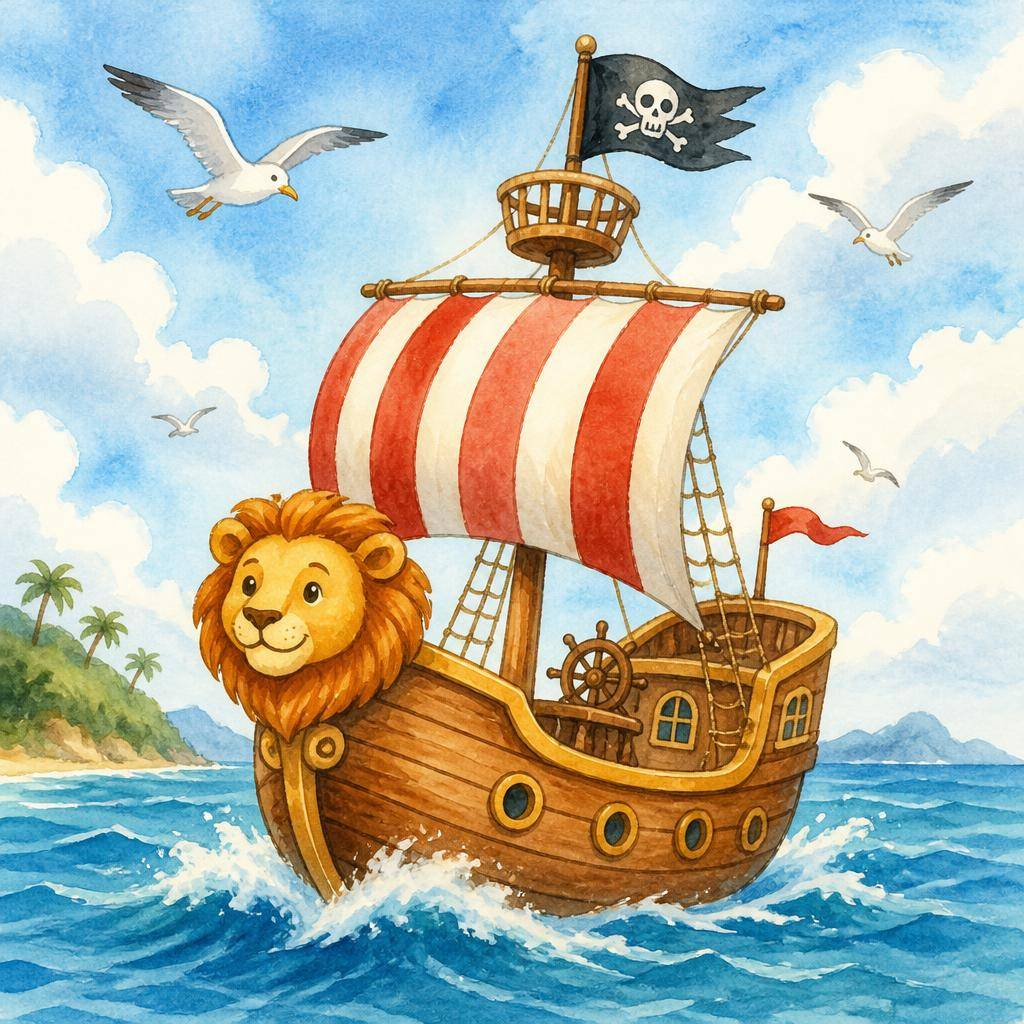

In [5]:
from IPython.display import Image as ShowImage, display

gen_path = DATA / "gen_ship.jpg"
prompt = (
    "A small wooden pirate ship with a friendly lion-head figurehead sailing on a bright sea, "
    "children's picture book watercolor style, seagulls, no text"
)

if gen_path.exists():
    print("已有圖檔，直接讀：", gen_path)
elif HAS_KEY:
    t = time.perf_counter()
    r = client.images.generate(
        model=IMAGE_MODEL, prompt=prompt, size="1024x1024", quality="low",
        output_format="jpeg", output_compression=70,
    )
    gen_path.write_bytes(base64.b64decode(r.data[0].b64_json))
    print(f"生成完成，花了 {time.perf_counter() - t:.1f} 秒，用量：{r.usage}")
else:
    skip("生成圖片")

if gen_path.exists():
    print(f"{gen_path}：{gen_path.stat().st_size / 1024:.0f} KB")
    display(ShowImage(filename=str(gen_path), width=320))

## Step 6：圖片 → 文字（看圖回答）

一個 `content` 陣列可以放好幾張圖。這裡一次送兩張：長條圖問數字，生成的圖要它描述。
長條圖要看清楚數字，用 `detail: "high"`；生成的圖只要大概，用 `detail: "low"` 省 token。

In [6]:
def image_part(path: Path, detail: str) -> dict:
    return {"type": "image_url", "image_url": {"url": to_data_url(path), "detail": detail}}


content = [
    {"type": "text", "text": "第一張圖：哪一天漁獲最多？大約幾公斤？"},
    image_part(chart_path, "high"),
]
if gen_path.exists():
    content += [{"type": "text", "text": "第二張圖：用一句話描述畫面。"}, image_part(gen_path, "low")]

if HAS_KEY:
    t = time.perf_counter()
    r = client.chat.completions.create(
        model=VISION_MODEL,
        messages=[
            {"role": "system", "content": "用繁體中文回答，每題一行。"},
            {"role": "user", "content": content},
        ],
        reasoning_effort="none",
        max_completion_tokens=300,
    )
    print(r.choices[0].message.content)
    print(f"\n花了 {time.perf_counter() - t:.1f} 秒；輸入 {r.usage.prompt_tokens} token（大部分是圖片），輸出 {r.usage.completion_tokens} token")
else:
    skip("看圖回答")
    print("（正確答案：週四最多，31 公斤）")

第一張圖：週四漁獲最多，大約 31 公斤。  
第二張圖：一艘帶著海盜旗、獅子駕船的帆船在海上航行，周圍有海鷗飛翔。

花了 3.4 秒；輸入 1433 token（大部分是圖片），輸出 63 token


對答案：週四、31 公斤。輸入 token 數遠多於那兩句問題的長度，多出來的就是圖片。

本機也能看圖：Ollama 有視覺模型（例如 `qwen2.5vl`），請求格式一樣是 `content` 陣列，只是 base_url 換成本機。
這門課的機器顯存有限，不在這裡下載。

## Step 7：文字 → 語音

`audio.speech` 輸入一段文字，回傳音檔。`gpt-4o-mini-tts` 可以用 `instructions` 指定語氣，這是它跟舊的 `tts-1` 最大的差別。
下面這句台詞是自己寫的，等一下會拿它做「語音 → 文字」的閉環測試：唸出來再聽回去，比對有沒有走樣。

In [7]:
from IPython.display import Audio

LINE = "魯夫站在千陽號的船頭大喊：下一座島，我們一定要找到最好吃的肉！"
tts_path = DATA / "luffy_line.mp3"

if tts_path.exists():
    print("已有音檔，直接讀：", tts_path)
elif HAS_KEY:
    t = time.perf_counter()
    r = client.audio.speech.create(
        model=TTS_MODEL, voice="coral", input=LINE,
        instructions="用台灣口音的中文，語氣興奮、充滿冒險感，速度中等。",
        response_format="mp3",
    )
    tts_path.write_bytes(r.content)
    print(f"生成完成，花了 {time.perf_counter() - t:.1f} 秒")
else:
    skip("文字轉語音")

if tts_path.exists():
    print(f"{tts_path}：{tts_path.stat().st_size / 1024:.0f} KB")
    display(Audio(filename=str(tts_path)))

生成完成，花了 2.7 秒
data/luffy_line.mp3：134 KB


## Step 8：聲音進模型前長什麼樣

音檔是一長串振幅（每秒 16000 個數字）。Whisper 不直接吃這串數字，而是先轉成 **log-mel 頻譜圖**：
橫軸是時間、縱軸是 80 個頻帶、顏色是能量。換句話說，**聲音被變成一張圖**，後面就跟你熟悉的影像模型很像了。

除了自己做的中文音檔，再拿一段公開的英文朗讀（LibriSpeech 測試用的小樣本）當對照。

In [8]:
import datasets
import numpy as np
from transformers import WhisperFeatureExtractor
from transformers.pipelines.audio_utils import ffmpeg_read

SR = 16000
ds = datasets.load_dataset("hf-internal-testing/librispeech_asr_dummy", "clean", split="validation")
ds = ds.cast_column("audio", datasets.Audio(decode=False))  # 自己用 ffmpeg 解碼，不另外裝套件
en_audio = ffmpeg_read(ds[0]["audio"]["bytes"], SR)
en_text = ds[0]["text"]

clips = {"英文朗讀": en_audio}
if tts_path.exists():
    clips["中文台詞（TTS）"] = ffmpeg_read(tts_path.read_bytes(), SR)

for name, wav in clips.items():
    print(f"{name}：{len(wav):,} 個取樣點＝{len(wav) / SR:.1f} 秒")

英文朗讀：93,680 個取樣點＝5.9 秒
中文台詞（TTS）：137,088 個取樣點＝8.6 秒


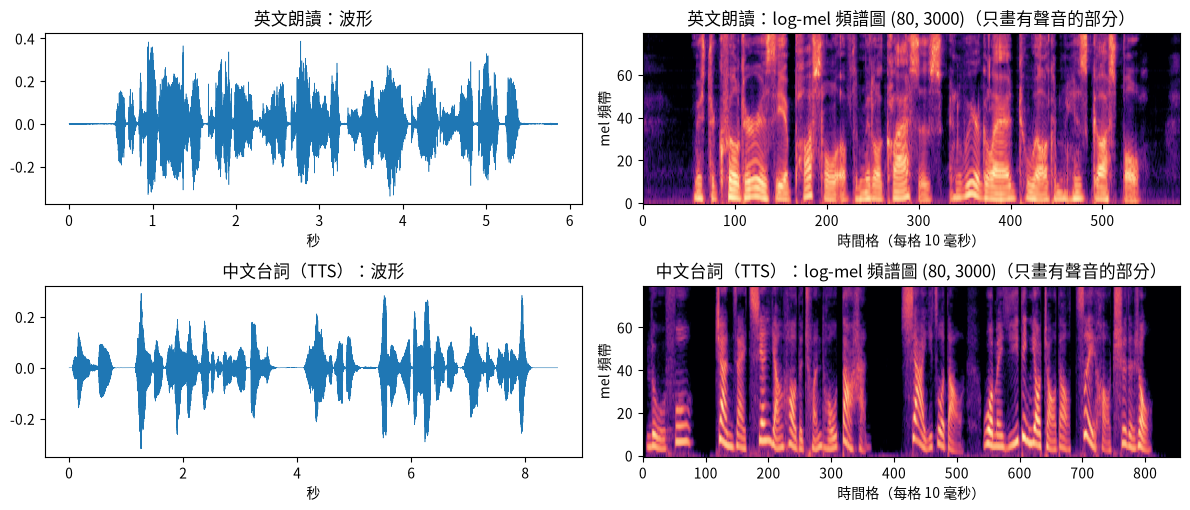

In [9]:
fe = WhisperFeatureExtractor.from_pretrained("openai/whisper-tiny")

fig, axes = plt.subplots(len(clips), 2, figsize=(12, 2.6 * len(clips)), squeeze=False)
for row, (name, wav) in zip(axes, clips.items()):
    row[0].plot(np.arange(len(wav)) / SR, wav, lw=0.4)
    row[0].set_title(f"{name}：波形")
    row[0].set_xlabel("秒")
    mel = fe(wav, sampling_rate=SR, return_tensors="np").input_features[0]
    frames = int(len(wav) / SR * 100)  # 每秒 100 格；後面是補零
    row[1].imshow(mel[:, :frames], aspect="auto", origin="lower", cmap="magma")
    row[1].set_title(f"{name}：log-mel 頻譜圖 {mel.shape}（只畫有聲音的部分）")
    row[1].set_xlabel("時間格（每格 10 毫秒）")
    row[1].set_ylabel("mel 頻帶")
plt.tight_layout()
plt.show()

不管音檔多長，Whisper 都把它補零或切成 30 秒、80 × 3000 的頻譜圖，這就是它的固定輸入大小。

## Step 9：語音 → 文字，在本機跑

`transformers` 的 `pipeline` 一行就能載入 Whisper。`whisper-tiny` 只有 3900 萬參數，筆電 CPU 也跑得動。
指定 `language` 可以避免它猜錯語言。

In [10]:
import torch
from transformers import pipeline

asr = pipeline(
    "automatic-speech-recognition", model="openai/whisper-tiny",
    device=0 if torch.cuda.is_available() else -1,
)


def transcribe_local(wav: np.ndarray, language: str) -> tuple[str, float]:
    t = time.perf_counter()
    out = asr({"raw": wav, "sampling_rate": SR}, generate_kwargs={"language": language, "task": "transcribe"})
    return out["text"].strip(), time.perf_counter() - t


en_local, sec = transcribe_local(en_audio, "en")
print(f"正確答案：{en_text}")
print(f"whisper-tiny（{sec:.2f} 秒）：{en_local}")

正確答案：MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELCOME HIS GOSPEL
whisper-tiny（0.46 秒）：Mr. Quilter is the apostle of the middle classes and we are glad to welcome his gospel.


In [11]:
zh_local = None
if "中文台詞（TTS）" in clips:
    zh_local, sec = transcribe_local(clips["中文台詞（TTS）"], "zh")
    print(f"正確答案：{LINE}")
    print(f"whisper-tiny（{sec:.2f} 秒）：{zh_local}")
else:
    print("沒有中文音檔（Step 7 被略過），這步跳過。")

正確答案：魯夫站在千陽號的船頭大喊：下一座島，我們一定要找到最好吃的肉！
whisper-tiny（0.14 秒）：祝福 站在千陽號的傳頭大寒下一座島我們一定要找到最好吃的肉


英文幾乎全對（只差在 MISTER 寫成 Mr.）。中文錯在同音字：人名「魯夫」聽成「祝福」、「船頭大喊」變成「傳頭大寒」；換一段話也可能輸出成簡體字。
原因很單純：tiny 是最小的版本，訓練資料又以英文為主。
本機要更準，換 `openai/whisper-small` 或更大的版本（下載和運算都會變多）。

## Step 10：語音 → 文字，用雲端

上傳音檔到 `audio.transcriptions`。`prompt` 可以給一點提示（例如專有名詞、要繁體字），對中文幫助很大。

In [12]:
zh_cloud = None
if not tts_path.exists():
    print("沒有中文音檔（Step 7 被略過），這步跳過。")
elif HAS_KEY:
    t = time.perf_counter()
    with tts_path.open("rb") as f:
        r = client.audio.transcriptions.create(
            model=STT_MODEL, file=f, language="zh", prompt="以下是繁體中文，提到海賊王的魯夫和千陽號。"
        )
    zh_cloud = r.text.strip()
    print(f"正確答案：{LINE}")
    print(f"{STT_MODEL}（{time.perf_counter() - t:.2f} 秒）：{zh_cloud}")
else:
    skip("雲端語音轉文字")

正確答案：魯夫站在千陽號的船頭大喊：下一座島，我們一定要找到最好吃的肉！
gpt-4o-mini-transcribe（1.57 秒）：魯夫站在千陽號的船頭大喊,下一座島,我們一定要找到最好吃的肉!


## Step 11：把三個結果放在一起比

用字元層級的相似度（0～1，1 是完全一樣）打分數。先拿掉標點和空白，英文轉小寫，只比內容。

whisper-tiny 英文                     0.97
whisper-tiny 中文                     0.86
gpt-4o-mini-transcribe 中文           1.00


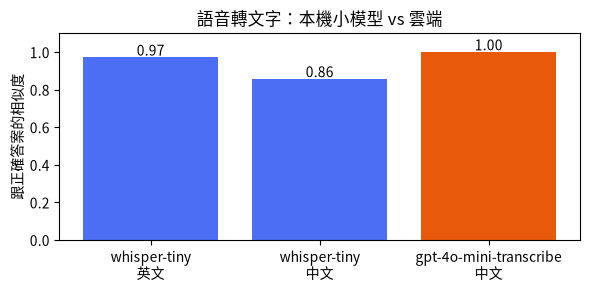

In [13]:
import difflib
import re


def similarity(ref: str, hyp: str) -> float:
    def norm(s: str) -> str:
        return re.sub(r"[^\w]", "", s.lower())

    return difflib.SequenceMatcher(None, norm(ref), norm(hyp)).ratio()


results = {"whisper-tiny\n英文": similarity(en_text, en_local)}
if zh_local is not None:
    results["whisper-tiny\n中文"] = similarity(LINE, zh_local)
if zh_cloud is not None:
    results[f"{STT_MODEL}\n中文"] = similarity(LINE, zh_cloud)

for k, v in results.items():
    print(f"{k.replace(chr(10), ' '):<35} {v:.2f}")

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(list(results), list(results.values()), color=["#4c6ef5", "#4c6ef5", "#e8590c"][: len(results)])
ax.bar_label(bars, fmt="%.2f")
ax.set_ylim(0, 1.1)
ax.set_ylabel("跟正確答案的相似度")
ax.set_title("語音轉文字：本機小模型 vs 雲端")
plt.tight_layout()
plt.show()

看圖時注意：0.86 聽起來不差，但錯的正好是人名這種最關鍵的字。雲端拿到滿分，`prompt` 裡先提示「魯夫」「千陽號」也有功勞。
實務的選法：資料不能出門、量很大、英文為主 → 本機 Whisper；中文、要準、量不大 → 雲端。

## 試試看

1. 在 Step 6 把長條圖的 `detail` 改成 `"low"`，比較輸入 token 數，答案還對嗎？
2. 改寫 Step 7 的 `instructions`（例如「像在講悄悄話」），刪掉 `data/luffy_line.mp3` 重跑，再看 Step 11 的分數有沒有變。
3. 把 Step 9 的模型換成 `openai/whisper-small`（約 1GB），中文分數能追上雲端嗎？花了幾秒？

## 小結

- 圖片放進 `messages` 的方式：`content` 改成陣列，圖片用網址或 base64；圖片也按 token 計費。
- 生成圖片、文字轉語音、語音轉文字是各自的端點；聲音進模型前先變成 log-mel 頻譜圖。
- 本機 Whisper 免費、資料不出門，但小模型中文弱。下一本：同一份程式碼怎麼換到 Ollama、OpenRouter、Anthropic 等不同供應商。